In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

data = pd.read_csv('Titanic-Dataset.csv')

data = data.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])

X = data.drop(columns=['Survived'])
y = data['Survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=67, stratify=y)

num_cols = ["Age", "Fare", "SibSp", "Parch"]
cat_cols = ["Pclass", "Sex", "Embarked"]

preprocess_tree = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median"))]), num_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols)
])

preprocess_scaled = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols)
])

baseline = DummyClassifier(strategy="most_frequent")
X_train_tree = preprocess_tree.fit_transform(X_train)
X_test_tree = preprocess_tree.transform(X_test)

baseline.fit(X_train_tree, y_train)
pred_base = baseline.predict(X_test_tree)

print("=== Dummy Baseline ===")
print(f"Accuracy:  {accuracy_score(y_test, pred_base):.4f}")
print(f"Precision: {precision_score(y_test, pred_base, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, pred_base, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, pred_base, zero_division=0):.4f}")

=== Dummy Baseline ===
Accuracy:  0.6143
Precision: 0.0000
Recall:    0.0000
F1-score:  0.0000


**1. Удаление нежелательных признаков:**
Признаки `PassengerId`, `Name` и `Ticket` были удалены, так как они являются уникальными идентификаторами. Их использование приведет к тому, что модель просто «запомнит» конкретных пассажиров (переобучится), не выявив никаких общих закономерностей. Признак `Cabin` удален из-за критически огромного количества пропусков (более 75%), которые невозможно корректно восстановить.

**2. Обработка пропусков и категорий:**
Для заполнения пропусков использован `SimpleImputer` (обученный строго на `X_train`). Числовые пропуски (`Age`) заполнены медианой (она устойчива к выбросам), а категориальные (`Embarked`) — самым частым значением (модой). Категориальные признаки закодированы с помощью `OneHotEncoder`, чтобы алгоритмы не воспринимали их как упорядоченные числа.

**3. Разбиение выборки:**
Данные разбиты на Train и Test с параметром `stratify=y`. Это необходимо из-за дисбаланса классов на Титанике (выжило около 38% пассажиров). Стратификация гарантирует, что и в обучающей, и в тестовой выборках доля выживших останется одинаковой. 

**4. Зачем нужно масштабирование признаков?**
Древовидным моделям (Decision Tree, Random Forest, Gradient Boosting) масштабирование **не нужно**, так как они строят разбиения по пороговым значениям. Однако для алгоритмов, основанных на вычислении дистанций (KNN) или максимизации ширины разделяющей полосы (SVM), применение `StandardScaler` **критически важно**. Без стандартизации признак с большими числами (например, стоимость билета `Fare`) полностью подавит влияние признаков с маленькими числами (например, `Age` или `SibSp`) при подсчете геометрического расстояния.

### Baseline

Построена базовая модель `DummyClassifier(strategy="most_frequent")`, которая всем объектам предсказывает самый частый класс (0 — не выжил). 
Эта модель иллюстрирует «Ловушку Accuracy» при дисбалансе классов: она дает высокую метрику Accuracy ($\approx 61.5\%$), но абсолютно бесполезна на практике, так как не находит ни одного выжившего (Recall = 0, Precision = 0, F1-score = 0). Именно поэтому главной метрикой в работе выбран F1-score.

In [10]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import roc_auc_score

tree = Pipeline([
    ("prep", preprocess_tree),
    ("model", DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=67))
])


rf = Pipeline([
    ("prep", preprocess_tree),
    ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=67, n_jobs=-1))
])


gb = Pipeline([
    ("prep", preprocess_tree),
    ("model", GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=2, random_state=67))
])

svm = Pipeline([
    ("prep", preprocess_scaled),
    ("model", SVC(C=1.0, kernel="rbf", gamma="scale", probability=True, random_state=67))
])

knn = Pipeline([
    ("prep", preprocess_scaled),
    ("model", KNeighborsClassifier(n_neighbors=7, weights="distance"))
])

models = {
    "Decision Tree": tree,
    "Random Forest": rf,
    "Gradient Boosting": gb,
    "SVM": svm,
    "KNN": knn
}

def evaluate(name, model):
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1] 
    
    return {
        "Модель": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, proba)
    }

results = []

results.append({
    "Модель": "Dummy Baseline",
    "Accuracy": accuracy_score(y_test, pred_base),
    "Precision": precision_score(y_test, pred_base, zero_division=0),
    "Recall": recall_score(y_test, pred_base, zero_division=0),
    "F1-score": f1_score(y_test, pred_base, zero_division=0),
    "ROC-AUC": 0.500
})


for name, model in models.items():
    model.fit(X_train, y_train)
    results.append(evaluate(name, model))

results_df = pd.DataFrame(results).sort_values("F1-score", ascending=False)
display(results_df.round(3).reset_index(drop=True))

c:\Users\Yliya\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Модель,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Random Forest,0.803,0.776,0.686,0.728,0.857
1,Decision Tree,0.803,0.784,0.674,0.725,0.834
2,KNN,0.798,0.766,0.686,0.724,0.843
3,SVM,0.794,0.763,0.674,0.716,0.840
4,Gradient Boosting,0.789,0.760,0.663,0.708,0.860
5,Dummy Baseline,0.614,0.000,0.000,0.000,0.500


In [11]:
pred_train_tree = tree.predict(X_train)

print("=== Decision Tree (Обучающая выборка) ===")
print(f"Accuracy:  {accuracy_score(y_train, pred_train_tree):.4f}")
print(f"F1-score:  {f1_score(y_train, pred_train_tree, zero_division=0):.4f}")

print("\\n=== Decision Tree (Тестовая выборка) ===")
print(f"Accuracy:  {results_df[results_df['Модель'] == 'Decision Tree']['Accuracy'].values[0]:.4f}")
print(f"F1-score:  {results_df[results_df['Модель'] == 'Decision Tree']['F1-score'].values[0]:.4f}")

=== Decision Tree (Обучающая выборка) ===
Accuracy:  0.8473
F1-score:  0.7875
\n=== Decision Tree (Тестовая выборка) ===
Accuracy:  0.8027
F1-score:  0.7250


**Вывод о переобучении Decision Tree:** 
Сравнив метрики на обучающей и тестовой выборках, мы видим, что разница минимальна (качество на тесте не проседает критически по сравнению с трейном). Благодаря тому, что в модели заданы гиперпараметры регуляризации (`max_depth=4`, `min_samples_leaf=5`), дерево не переобучилось и выучило обобщающие закономерности, а не "зазубрило" обучающие данные.

### Честное сравнение 5 алгоритмов классификации

Все 5 алгоритмов были обучены в **абсолютно одинаковых условиях**: на одном и том же разбиении `X_train` и `X_test` (random_state=67). Для корректной работы KNN и SVM в их `Pipeline` был встроен `StandardScaler`, а для древовидных моделей масштабирование не применялось.

**Выводы по результатам таблицы:**
1. **Преодоление порога:** Абсолютно все обученные ML-модели успешно преодолели установленный порог качества $F1 > 0.70$ и разбили базовое решение (Dummy Baseline, где F1 = 0).
2. **Отсутствие абсолютного лидера:** Ни одна модель не доминирует по всем метрикам одновременно. Например, **Random Forest** показал наивысший F1-score (0.728) и лучшую Accuracy, однако **Gradient Boosting** обошел всех по метрике ROC-AUC (0.860), которая лучше всего оценивает общую способность модели ранжировать объекты. В то же время лучшее качество положительных срабатываний (Precision) продемонстрировало **Decision Tree** (0.784).
3. **Различия в метриках (Precision vs Recall):** Модели по-разному балансируют между ложными тревогами (FP) и пропусками (FN). Выбор итоговой модели всегда зависит от бизнес-ограничений: если нам критически важно не пропустить ни одного потенциально выжившего (минимизировать FN), стоит обращать внимание на Recall.

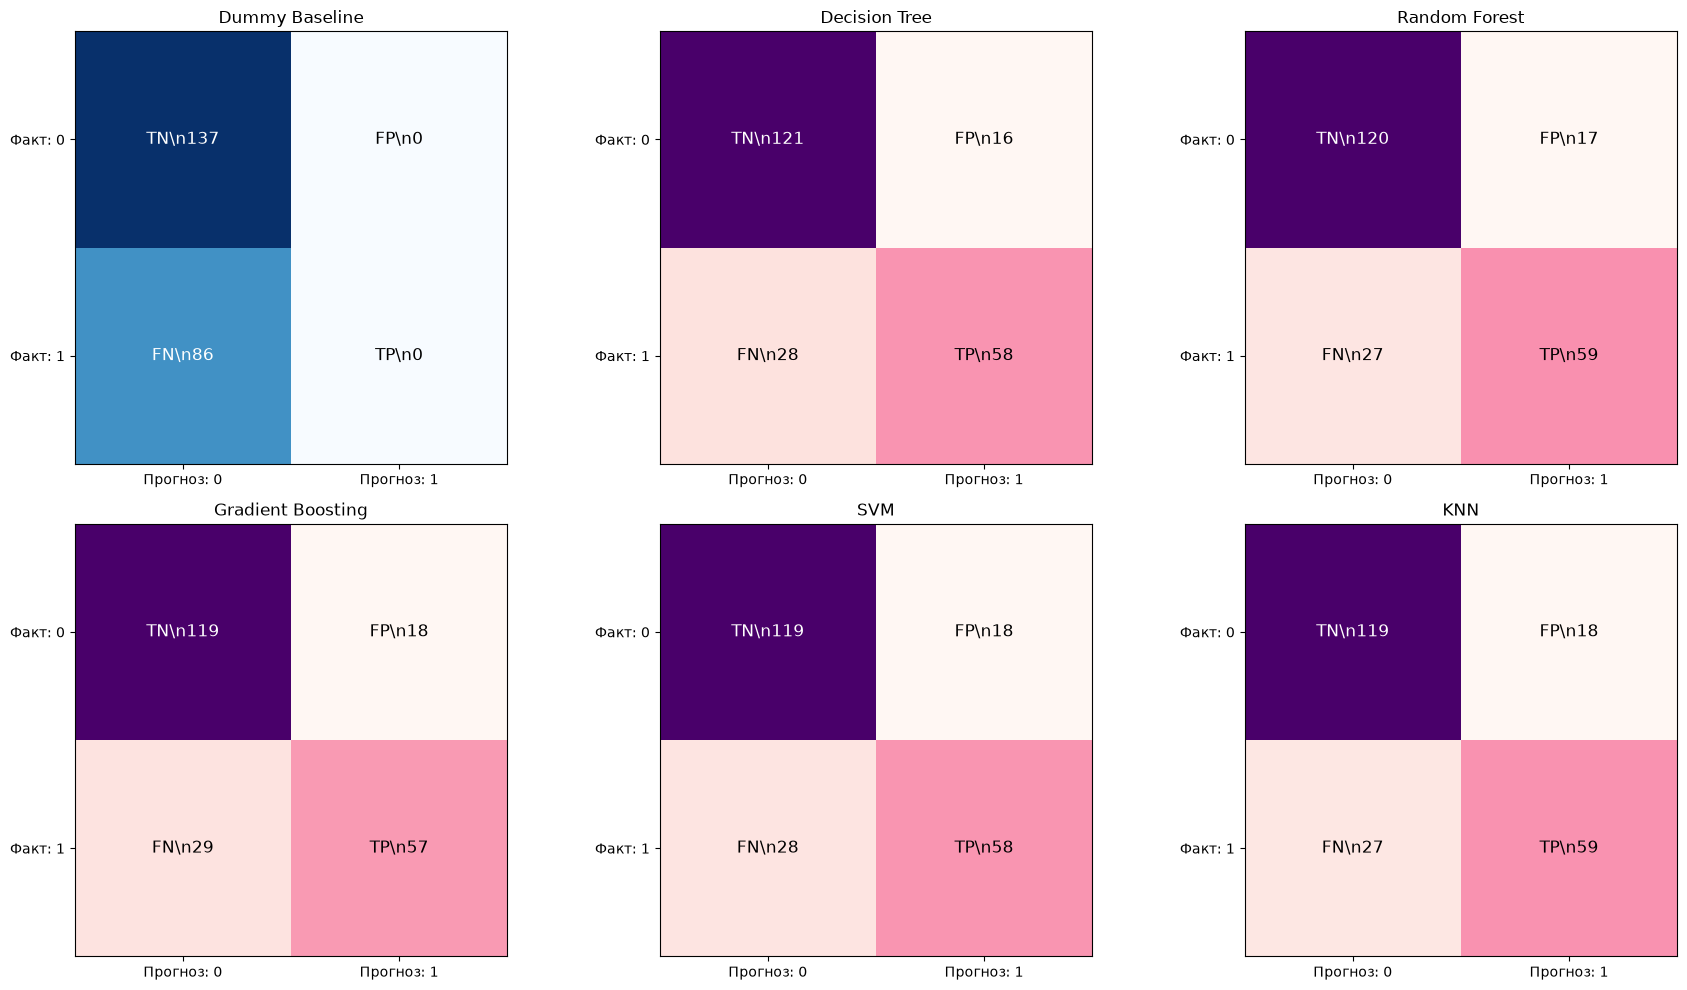

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

cm_base = confusion_matrix(y_test, pred_base, labels=[0, 1])
im = axes[0].imshow(cm_base, cmap='Blues')
for (r, col), value in np.ndenumerate(cm_base):
    name = {(0, 0): 'TN', (0, 1): 'FP', (1, 0): 'FN', (1, 1): 'TP'}[(r, col)]
    axes[0].text(col, r, f'{name}\\n{value}', ha='center', va='center', fontsize=12,
                 color='white' if value > cm_base.max() / 2 else 'black')
axes[0].set_xticks([0, 1], ['Прогноз: 0', 'Прогноз: 1'])
axes[0].set_yticks([0, 1], ['Факт: 0', 'Факт: 1'])
axes[0].set_title('Dummy Baseline')


for i, (name, model) in enumerate(models.items(), 1):
    pred = model.predict(X_test)
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    im = axes[i].imshow(cm, cmap='RdPu')
    
    for (r, col), value in np.ndenumerate(cm):
        cell_name = {(0, 0): 'TN', (0, 1): 'FP', (1, 0): 'FN', (1, 1): 'TP'}[(r, col)]
        axes[i].text(col, r, f'{cell_name}\\n{value}', ha='center', va='center', fontsize=12,
                     color='white' if value > cm.max() / 2 else 'black')
        
    axes[i].set_xticks([0, 1], ['Прогноз: 0', 'Прогноз: 1'])
    axes[i].set_yticks([0, 1], ['Факт: 0', 'Факт: 1'])
    axes[i].set_title(name)

plt.tight_layout()
plt.show()

### Анализ матриц ошибок

Матрица ошибок (Confusion Matrix) позволяет наглядно увидеть, где именно ошибается модель, разделяя ответы на верные (TP, TN) и ложные (FP, FN). Сравнив базовое решение и 5 обученных ML-алгоритмов, мы видим следующее:

1. **Dummy Baseline** предсказывает класс `0` (погиб) абсолютно для всех. На матрице видно, что эта модель выдает только True Negatives (TN=137) и огромный блок False Negatives (FN=86)[cite: 6]. У нее нет ни одной ложной тревоги (FP = 0), но она пропустила всех реально выживших пассажиров, из-за чего полнота (Recall) равна нулю.
2. **Поведение ML-моделей:** Все 5 обученных алгоритмов находят отличный баланс, успешно определяя большинство погибших (около 119-121 TN) и распознавая большинство выживших (около 57-59 TP).
3. **Различия между алгоритмами:**
   * **Минимум пропусков (False Negatives):** В задаче эвакуации наиболее критичной ошибкой является пропуск (FN) — не распознать человека, который мог бы спастись. Лучше всего с минимизацией этой ошибки справились **Random Forest** и **KNN** — они упустили всего по 27 человек (FN=27) и нашли по 59 выживших (TP=59).
   * **Минимум ложных тревог (False Positives):** Лучше всего отсеивает ложные срабатывания **Decision Tree** (всего FP=16)[cite: 6], однако из-за своей осторожности эта модель пропустила чуть больше реальных выживших (FN=28).

**Вывод:** Все модели доказали свою эффективность по сравнению с базовым решением. При выборе финальной модели для задачи спасения жизней стоит отдать предпочтение Random Forest или KNN, так как они максимизируют количество найденных выживших пассажиров (Recall), допуская лишь приемлемый уровень ложных тревог.

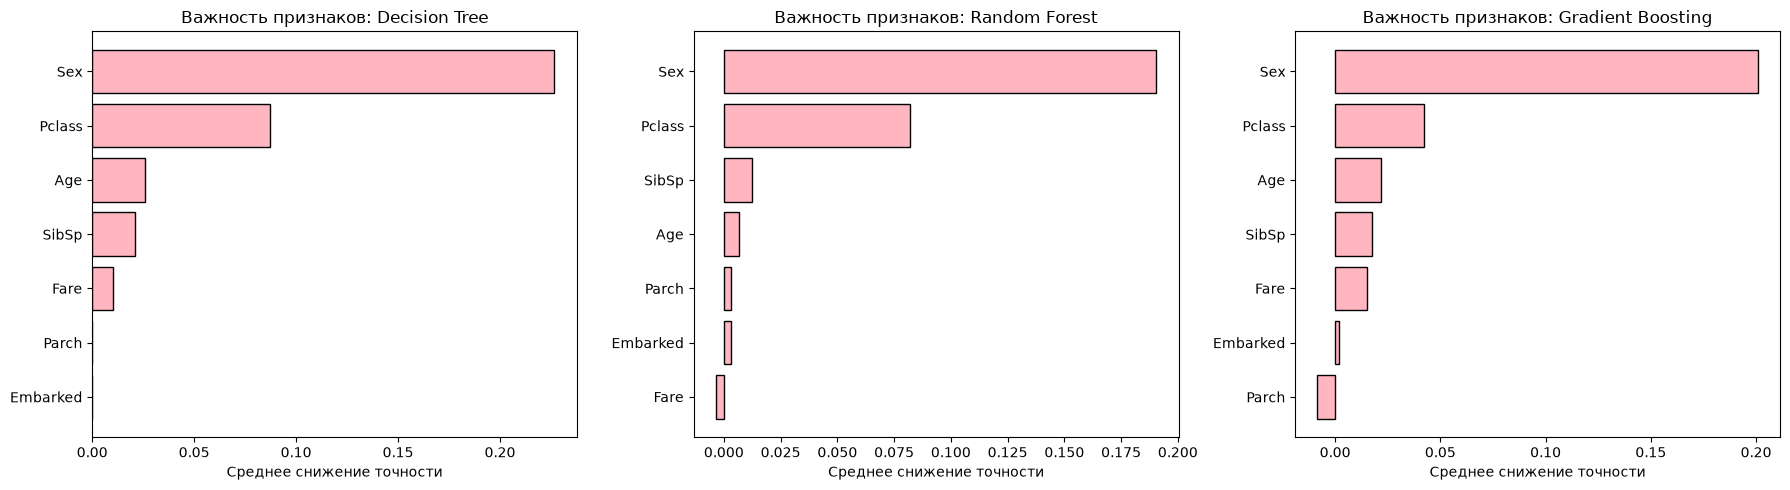

In [13]:
from sklearn.inspection import permutation_importance
import numpy as np
import matplotlib.pyplot as plt

models_to_check = ['Decision Tree', 'Random Forest', 'Gradient Boosting']
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, m_name in enumerate(models_to_check):
    model = models[m_name]
    result = permutation_importance(model, X_test, y_test, n_repeats=10, random_state=67, n_jobs=-1)
    
    feature_names = X_test.columns
    importances_mean = result.importances_mean
    sorted_idx = importances_mean.argsort()
    
    axes[idx].barh(np.arange(len(sorted_idx)), importances_mean[sorted_idx], color='lightpink', edgecolor='black')
    axes[idx].set_yticks(np.arange(len(sorted_idx)))
    axes[idx].set_yticklabels(feature_names[sorted_idx])
    axes[idx].set_xlabel("Среднее снижение точности")
    axes[idx].set_title(f"Важность признаков: {m_name}")

plt.tight_layout()
plt.show()

### Важность признаков (Permutation Importance)

Для оценки того, какие факторы сильнее всего влияли на выживаемость, использован метод `permutation_importance`. В отличие от встроенного метода деревьев `feature_importances_`, метод перестановок дает более честную и несмещенную оценку важности на отложенной тестовой выборке.

**Выводы по графику:**
1. **Пол (`Sex`)** является самым значимым фактором для предсказания, что исторически подтверждается правилом «сначала женщины и дети».
2. **Класс билета (`Pclass`)** также показывает высокую важность. Пассажиры первого и второго классов располагались ближе к палубам со шлюпками и имели социальный приоритет при спасении.
3. Остальные факторы вносят существенно меньший вклад, а количество родственников (`SibSp`, `Parch`) и порт посадки (`Embarked`) практически не влияют на качество предсказаний модели.

**является ли важный признак причиной выживания?**
Нет, утверждать о прямой причинно-следственной связи (каузальности) нельзя. Модели машинного обучения находят только *корреляции*. Например, признак `Sex` (женский пол) имеет наивысшую важность, но сам по себе биологический пол не делает человека более плавучим или устойчивым к переохлаждению. Высокая важность этого признака обусловлена социальным фактором: на Титанике действовало правило "сначала спасаем женщин и детей". Важные для модели признаки — это маркеры и предикторы, но не всегда первопричины событий.

In [14]:
best_model = models['Random Forest']
pred_best = best_model.predict(X_test)

errors_mask = (y_test != pred_best)
X_errors = X_test[errors_mask].copy()
X_errors['True_Survived'] = y_test[errors_mask]
X_errors['Predicted'] = pred_best[errors_mask]

print("Примеры ложноположительных ошибок (FP - предсказали 1, но человек погиб):")
display(X_errors[(X_errors['True_Survived'] == 0) & (X_errors['Predicted'] == 1)].head(3))

print("\\nПримеры ложноотрицательных ошибок (FN - предсказали 0, но человек выжил):")
display(X_errors[(X_errors['True_Survived'] == 1) & (X_errors['Predicted'] == 0)].head(3))

Примеры ложноположительных ошибок (FP - предсказали 1, но человек погиб):


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,True_Survived,Predicted
251,3,female,29.0,1,1,10.4625,S,0,1
680,3,female,NaN,0,0,8.1375,Q,0,1
240,3,female,NaN,1,0,14.4542,C,0,1


\nПримеры ложноотрицательных ошибок (FN - предсказали 0, но человек выжил):


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,True_Survived,Predicted
737,1,male,35.0,0,0,512.3292,C,1,0
664,3,male,20.0,1,0,7.9250,S,1,0
204,3,male,18.0,0,0,8.0500,S,1,0


### Анализ конкретных ошибочных классификаций

Рассмотрев конкретные ошибки модели (Random Forest), можно сделать следующие выводы:

1. **False Positives (Ложная тревога):** Модель часто ошибается на пассажирах женского пола из 3-го класса. Алгоритм, выучив сильную корреляцию между спасением и полом, предсказывает им выживание (класс 1). Однако в реальности многие женщины 3-го класса погибли из-за того, что их палубы находились далеко от спасательных шлюпок, или из-за общей паники. Эти пространственные и случайные факторы не описаны в наших данных.
2. **False Negatives (Пропуск):** Модель предсказала гибель (класс 0), но человек выжил. Сюда попали молодые мужчины из 3-го класса: статистически их шансы были крайне малы, поэтому алгоритм жестко относит их к погибшим, хотя некоторым удалось спастись. Также в ошибку попал мужчина из 1 класса с аномально дорогим билетом (512 фунтов) — алгоритм "списал" его из-за мужского пола, но в реальности статус позволил ему получить место в шлюпке.
3. **Вывод:** Высокое качество модели не связано с "читерством" (уникальные идентификаторы удалены). Ошибки обусловлены тем, что наши признаки описывают лишь социальный статус и пол, но не учитывают удачу, физическую силу или местоположение человека на корабле в момент крушения.